# 1, Calculation

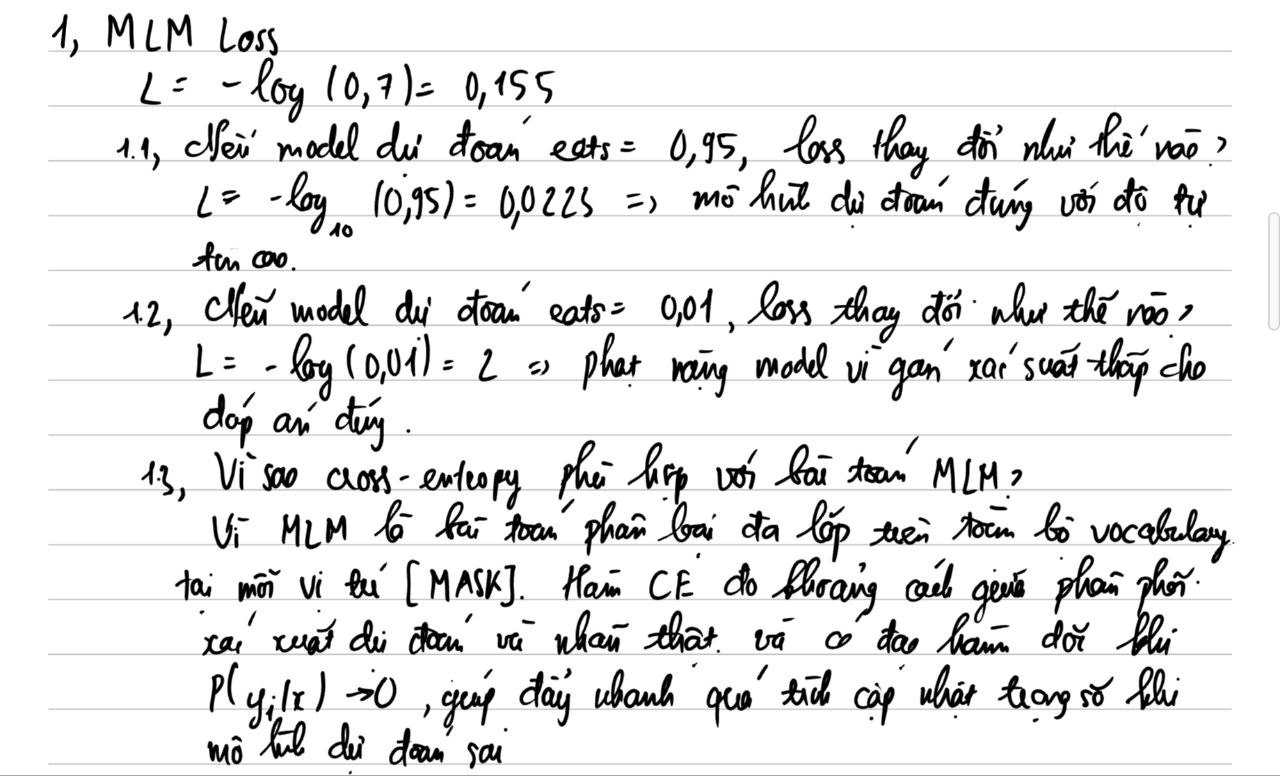

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
sample_text = "The cats are playing."
encoded = tokenizer(sample_text)

tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
print("\nToken sequence:", tokens)
print("Token IDs:", encoded["input_ids"])
print("Attention mask:", encoded["attention_mask"])


Token sequence: ['[CLS]', 'the', 'cats', 'are', 'playing', '.', '[SEP]']
Token IDs: [101, 1996, 8870, 2024, 2652, 1012, 102]
Attention mask: [1, 1, 1, 1, 1, 1, 1]


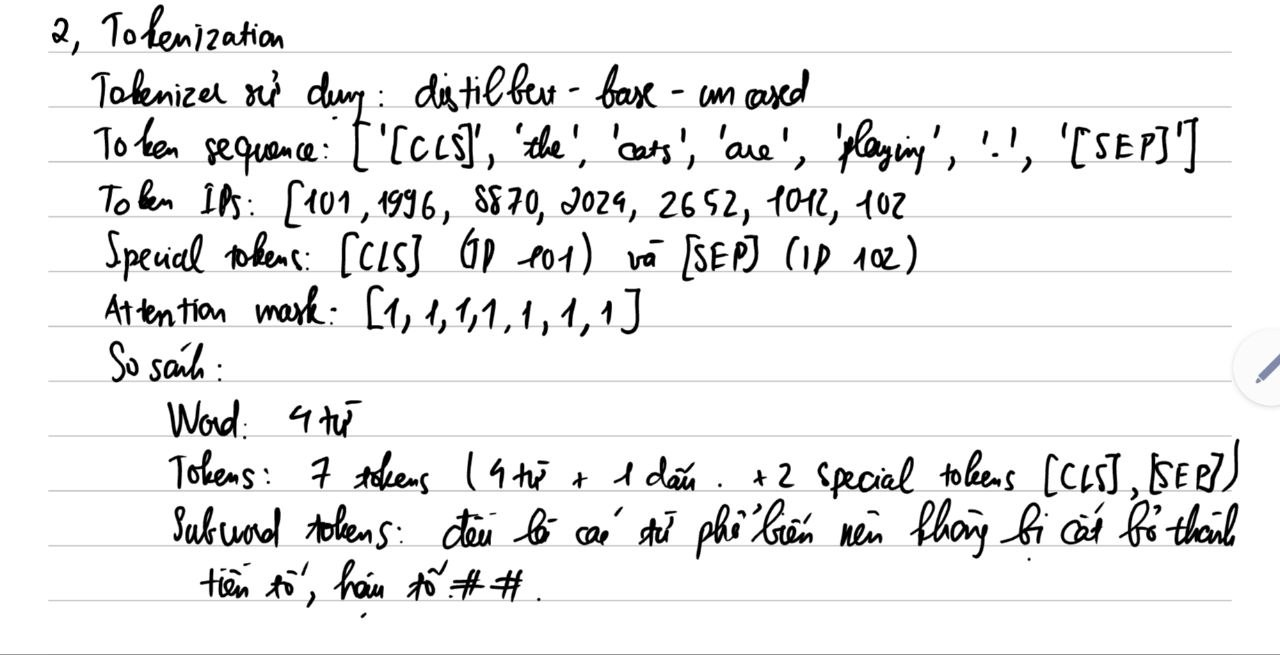

# 2, Prediction before experiment

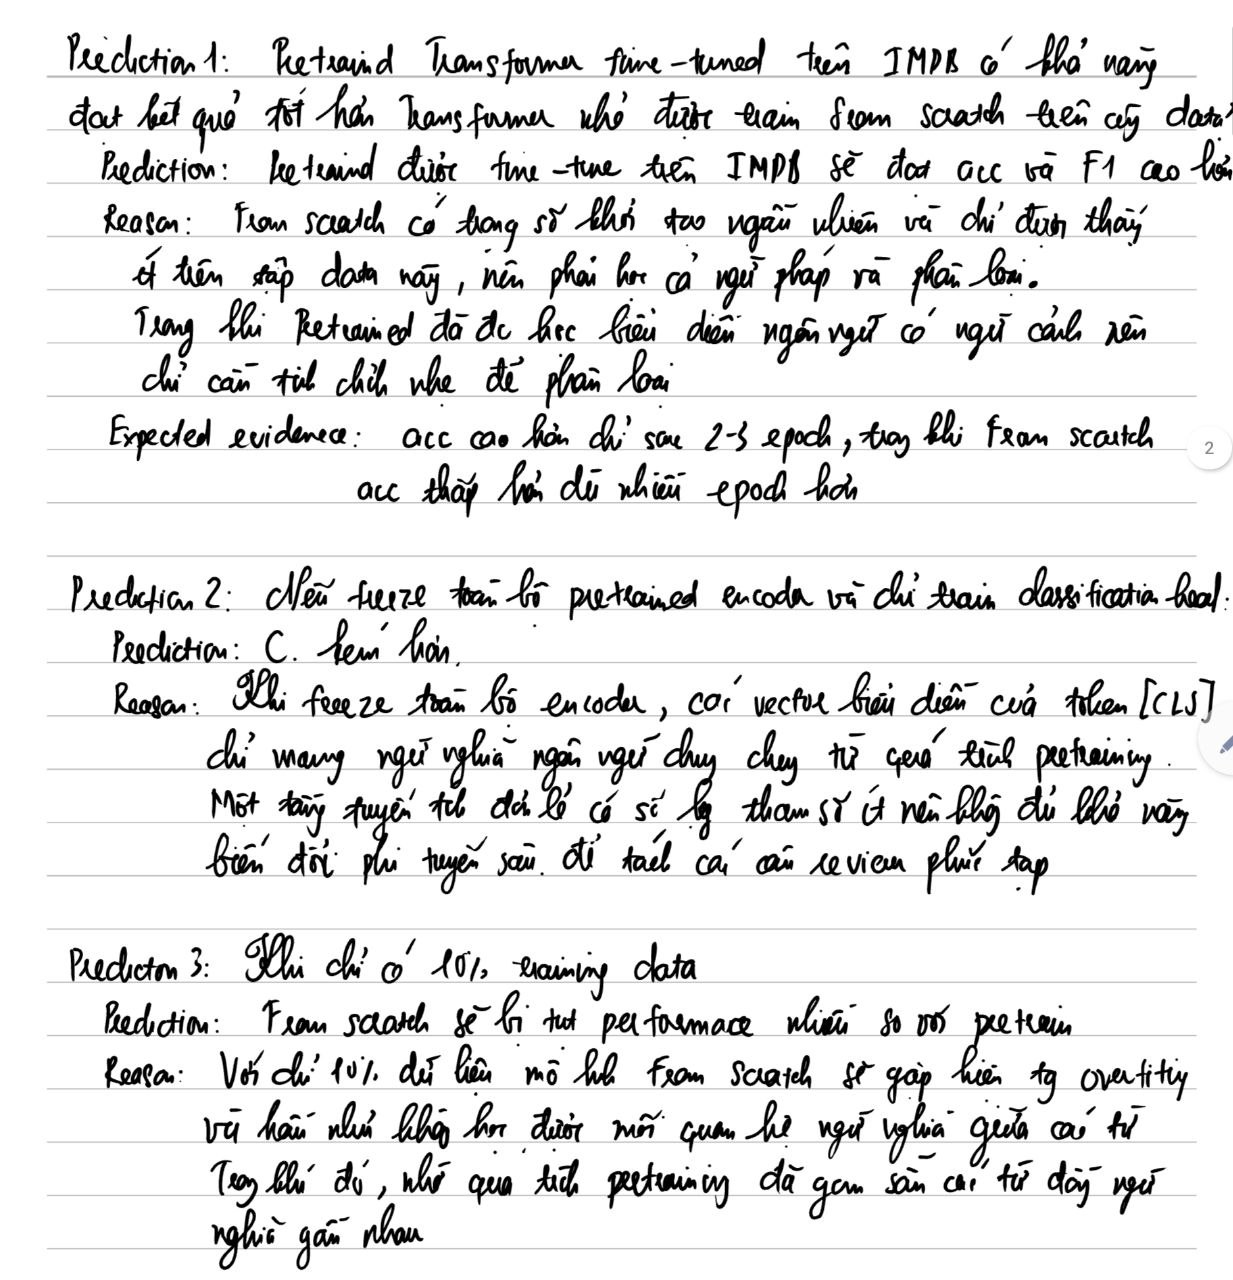

# 3, Tokenization & attention mask

In [ ]:
%cd /content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab08

/content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/lab08


In [ ]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

imdb = load_dataset("stanfordnlp/imdb", name="plain_text")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
all_texts = list(imdb["train"]["text"]) + list(imdb["test"]["text"])
all_labels = list(imdb["train"]["label"]) + list(imdb["test"]["label"])

idx = np.random.permutation(len(all_texts))
all_texts = [all_texts[i] for i in idx]
all_labels = [all_labels[i] for i in idx]

# 8:1:1
train_texts, train_labels = all_texts[:40000], all_labels[:40000]
val_texts, val_labels = all_texts[40000:45000], all_labels[40000:45000]
test_texts, test_labels = all_texts[45000:50000], all_labels[45000:50000]

print(f"Số mẫu thực nghiệm -> Train: {len(train_texts)}, Val: {len(val_texts)}, Test: {len(test_texts)}")

Số mẫu thực nghiệm -> Train: 40000, Val: 5000, Test: 5000


In [ ]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
sample_batch = [
    "This movie is great!",
    "I really hated the plot and the acting was terrible from start to finish."
]

tokens = tokenizer(
    sample_batch,
    padding=True,
    truncation=True,
    max_length=16,
    return_tensors="pt"
)

print("Các khóa trong tokens:", tokens.keys())
print("\ninput_ids:\n", tokens["input_ids"])
print("\nattention_mask:\n", tokens["attention_mask"])
print("\nGiải mã lại câu 1:", tokenizer.convert_ids_to_tokens(tokens["input_ids"][0]))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Các khóa trong tokens: KeysView({'input_ids': tensor([[ 101, 2023, 3185, 2003, 2307,  999,  102,    0,    0,    0,    0,    0,
            0,    0,    0,    0],
        [ 101, 1045, 2428, 6283, 1996, 5436, 1998, 1996, 3772, 2001, 6659, 2013,
         2707, 2000, 3926,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])})

input_ids:
 tensor([[ 101, 2023, 3185, 2003, 2307,  999,  102,    0,    0,    0,    0,    0,
            0,    0,    0,    0],
        [ 101, 1045, 2428, 6283, 1996, 5436, 1998, 1996, 3772, 2001, 6659, 2013,
         2707, 2000, 3926,  102]])

attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])

Giải mã lại câu 1: ['[CLS]', 'this', 'movie', 'is', 'great', '!', '[S

# 4, Pretrained model implementation

In [ ]:
max_len = 128
batch_size = 32

class IMDbDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_len,
            return_tensors="pt"
        )
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "label": self.labels[idx]
        }

train_dataset = IMDbDataset(train_texts, train_labels, tokenizer, max_len)
val_dataset = IMDbDataset(val_texts, val_labels, tokenizer, max_len)
test_dataset = IMDbDataset(test_texts, test_labels, tokenizer, max_len)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

In [ ]:
class PretrainedSentimentClassifier(nn.Module):
    def __init__(self, model_name="distilbert-base-uncased", num_classes=2, freeze_encoder=False):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)

        if freeze_encoder:
            for param in self.encoder.parameters():
                param.requires_grad = False

        hidden_size = self.encoder.config.hidden_size
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        # Lấy vector biểu diễn của token [CLS] (vị trí 0 đầu chuỗi)
        cls_rep = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(cls_rep)
        return logits

In [ ]:
def run_experiment(model, train_loader, val_loader, epochs=2, lr=2e-5):
    model = model.to(device)
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=lr)
    criterion = nn.CrossEntropyLoss()

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad()
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"  Epoch {epoch+1}/{epochs} - Train Loss: {total_loss/len(train_loader):.4f}")

    train_time = time.time() - start_time

    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids, attention_mask)
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(batch["label"].numpy())

    acc = accuracy_score(all_targets, all_preds)
    _, _, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average="binary", zero_division=0)
    num_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return acc, f1, train_time, num_trainable

# 5, From-scratch vs pretrained

In [ ]:
class ScratchTransformer(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, n_heads=2, max_len=128, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.pos_embedding = nn.Embedding(max_len, embed_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=n_heads, dim_feedforward=256, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, input_ids, attention_mask):
        b, seq_len = input_ids.shape
        pos = torch.arange(0, seq_len, device=input_ids.device).unsqueeze(0).expand(b, seq_len)
        x = self.embedding(input_ids) + self.pos_embedding(pos)
        pad_mask = (attention_mask == 0)
        x = self.transformer(x, src_key_padding_mask=pad_mask)
        cls_rep = x[:, 0, :]
        return self.fc(cls_rep)

print("1. Model A: Transformer From Scratch...")
scratch_model = ScratchTransformer(vocab_size=tokenizer.vocab_size, embed_dim=128, n_heads=2, max_len=max_len)
acc_scratch, f1_scratch, time_scratch, params_scratch = run_experiment(
    scratch_model, train_loader, val_loader, epochs=3, lr=1e-3
)

print("\n2. Model B: Pretrained Transformer (Fine-tuning)...")
pretrained_model = PretrainedSentimentClassifier(freeze_encoder=False)
acc_pre, f1_pre, time_pre, params_pre = run_experiment(
    pretrained_model, train_loader, val_loader, epochs=2, lr=2e-5
)

print("\nEXPERIMENT 1")
print(f"From Scratch -> Acc: {acc_scratch:.4f}, F1: {f1_scratch:.4f}, Time: {time_scratch:.1f}s, Params: {params_scratch:,}")
print(f"Pretrained   -> Acc: {acc_pre:.4f}, F1: {f1_pre:.4f}, Time: {time_pre:.1f}s, Params: {params_pre:,}")

1. Model A: Transformer From Scratch...
  Epoch 1/3 - Train Loss: 0.5281
  Epoch 2/3 - Train Loss: 0.3666
  Epoch 3/3 - Train Loss: 0.2902


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(



2. Model B: Pretrained Transformer (Fine-tuning)...


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 - Train Loss: 0.3294
  Epoch 2/2 - Train Loss: 0.2154

EXPERIMENT 1
From Scratch -> Acc: 0.8270, F1: 0.8300, Time: 53.1s, Params: 4,188,418
Pretrained   -> Acc: 0.8646, F1: 0.8748, Time: 904.5s, Params: 66,364,418


1. Representation khác nhau như thế nào?

- Ở mô hình From scratch, các vector embedding và trọng số attention ban đầu hoàn toàn ngẫu nhiên, chỉ học được mối liên hệ thống kê nông giữa các từ xuất hiện trong tập train IMDb. Ngược lại, Pretrained Transformer tạo ra các biểu diễn ngữ cảnh sâu (contextual representations), phân biệt được từ đa nghĩa, cấu trúc ngữ pháp và sắc thái biểu cảm nhờ đã được huấn luyện trên kho văn bản khổng lồ từ trước

2. Training data cần thiết khác nhau như thế nào?

- Mô hình From scratch đòi hỏi lượng dữ liệu có nhãn rất lớn để tránh học vẹt (overfitting) và hội tụ được các tầng Self-Attention. Trong khi đó, Pretrained model chỉ cần một lượng nhỏ dữ liệu gán nhãn để tinh chỉnh ranh giới phân loại cho tác vụ mục tiêu.

3. Chi phí tính toán khác nhau như thế nào?

- Pretrained model có số lượng tham số lớn hơn gấp nhiều lần so với vài triệu của mạng nhỏ tự tạo, dẫn đến thời gian chạy mỗi bước (step) và mức tiêu thụ bộ nhớ VRAM cao hơn. Tuy nhiên, nó chỉ cần 2–3 epochs để đạt đỉnh hiệu năng, trong khi train một mô hình lớn tương đương từ đầu sẽ tốn chi phí tính toán khổng lồ.

4. Kết quả có phù hợp với prediction không?

- Kết quả không hoàn toàn khớp với Prediction 1: Khi có lượng dữ liệu có nhãn rất lớn thì Pretrained Transformer chỉ cao mô hình huấn luyện từ đầu một chút cả về Accuracy lẫn F1-score.

# 6, Frozen vs fine-tuning

In [ ]:
print("Mode A: Pretrained Transformer (Frozen Encoder)...")
frozen_model = PretrainedSentimentClassifier(freeze_encoder=True)
acc_frozen, f1_frozen, time_frozen, params_frozen = run_experiment(
    frozen_model, train_loader, val_loader, epochs=2, lr=1e-3
)

print("\nKẾT QUẢ EXPERIMENT 2")
print(f"Frozen      -> Trainable: No  | Acc: {acc_frozen:.4f} | F1: {f1_frozen:.4f} | Time: {time_frozen:.1f}s | Trainable Params: {params_frozen:,}")
print(f"Fine-tuning -> Trainable: Yes | Acc: {acc_pre:.4f} | F1: {f1_pre:.4f} | Time: {time_pre:.1f}s | Trainable Params: {params_pre:,}")

Mode A: Pretrained Transformer (Frozen Encoder)...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 - Train Loss: 0.4749
  Epoch 2/2 - Train Loss: 0.4379

KẾT QUẢ EXPERIMENT 2
Frozen      -> Trainable: No  | Acc: 0.8040 | F1: 0.7926 | Time: 294.0s | Trainable Params: 1,538
Fine-tuning -> Trainable: Yes | Acc: 0.8646 | F1: 0.8748 | Time: 904.5s | Trainable Params: 66,364,418


Vì sao frozen encoder vẫn có thể thực hiện classification?

- Bởi vì bộ mã hóa pretrained đã học được cách trích xuất đặc trưng ngữ nghĩa và cú pháp tổng quát rất giàu thông tin từ kho văn bản lớn. Vector [CLS] đầu ra tự thân đã gom các câu có ý nghĩa tích cực và tiêu cực vào các vùng không gian tương đối tách biệt nhau với độ chính xác khá tốt (~80.4%)

Vì sao fine-tuning có thể cải thiện kết quả?

- Khi cho phép fine-tuning toàn bộ encoder, các trọng số Self-Attention ở mọi tầng được điều chỉnh lại để tập trung mạnh hơn vào các từ khóa mang tính đánh giá, giúp biểu diễn của [CLS] trở nên chuyên biệt cho bài toán phân loại cảm xúc trên IMDb và đẩy F1-score tăng lên ~87,48%.

# 7, Data-efficiency experiment


10% dữ liệu (4000 mẫu)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 - Train Loss: 0.4553
  Epoch 2/2 - Train Loss: 0.2630
  Epoch 1/3 - Train Loss: 0.6870
  Epoch 2/3 - Train Loss: 0.6288
  Epoch 3/3 - Train Loss: 0.5076

25% dữ liệu (10000 mẫu)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

  Epoch 1/2 - Train Loss: 0.3537
  Epoch 2/2 - Train Loss: 0.2315
  Epoch 1/3 - Train Loss: 0.5853
  Epoch 2/3 - Train Loss: 0.4090
  Epoch 3/3 - Train Loss: 0.2996

100% dữ liệu (40000 mẫu)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/2 - Train Loss: 0.3284
  Epoch 2/2 - Train Loss: 0.2171
  Epoch 1/3 - Train Loss: 0.5555
  Epoch 2/3 - Train Loss: 0.3838
  Epoch 3/3 - Train Loss: 0.2981


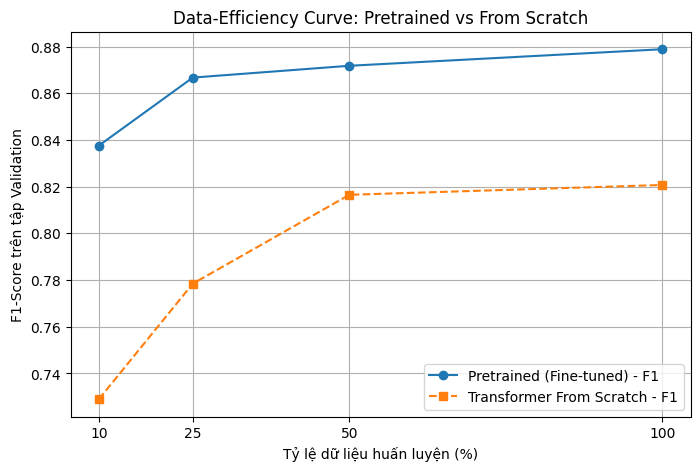

In [ ]:
fractions = [0.1, 0.25, 0.5, 1.0]
pre_accs, pre_f1s = [], []
scr_accs, scr_f1s = [], []

for frac in fractions:
    sub_size = int(len(train_dataset) * frac)
    sub_dataset = Subset(train_dataset, range(sub_size))
    sub_loader = DataLoader(sub_dataset, batch_size=batch_size, shuffle=True)

    print(f"\n{int(frac*100)}% dữ liệu ({sub_size} mẫu)")
    m_pre = PretrainedSentimentClassifier(freeze_encoder=False)
    a_p, f_p, _, _ = run_experiment(m_pre, sub_loader, val_loader, epochs=2, lr=2e-5)
    pre_accs.append(a_p)
    pre_f1s.append(f_p)

    m_scr = ScratchTransformer(vocab_size=tokenizer.vocab_size, embed_dim=128, n_heads=2, max_len=max_len)
    a_s, f_s, _, _ = run_experiment(m_scr, sub_loader, val_loader, epochs=3, lr=1e-3)
    scr_accs.append(a_s)
    scr_f1s.append(f_s)

pcts = [10, 25, 50, 100]
plt.figure(figsize=(8, 5))
plt.plot(pcts, pre_f1s, marker="o", label="Pretrained (Fine-tuned) - F1")
plt.plot(pcts, scr_f1s, marker="s", linestyle="--", label="Transformer From Scratch - F1")
plt.xlabel("Tỷ lệ dữ liệu huấn luyện (%)")
plt.ylabel("F1-Score trên tập Validation")
plt.title("Data-Efficiency Curve: Pretrained vs From Scratch")
plt.xticks(pcts)
plt.legend()
plt.grid(True)
plt.savefig("data_efficiency.png", dpi=150)
plt.show()

Pretraining có giúp model sử dụng dữ liệu downstream hiệu quả hơn không?

- Có. Quan sát toàn bộ đường cong, ta thấy ngay tại mốc 10% dữ liệu, mô hình Pretrained đã đạt F1 ~0.84 (cao hơn cả mô hình From-Scratch khi dùng toàn bộ 100% dữ liệu là ~0.82). Khi giảm dữ liệu từ 100% xuống 10%, đường cong của Pretrained chỉ giảm nhẹ và giữ độ dốc thoải, trong khi đường cong của mô hình From-Scratch lao dốc thẳng đứng từ ~0.82 xuống ~0.73. Điều này chứng minh tri thức ngôn ngữ học được từ pretraining giúp mô hình tiết kiệm dữ liệu gán nhãn hơn rất nhiều.

In [ ]:
# Experiment 4
for seq_l in [64, 128, 256]:
    ds_tr = IMDbDataset(train_texts[:1000], train_labels[:1000], tokenizer, seq_l)
    ds_va = IMDbDataset(val_texts, val_labels, tokenizer, seq_l)
    ld_tr = DataLoader(ds_tr, batch_size=16, shuffle=True)
    ld_va = DataLoader(ds_va, batch_size=16)
    m_len = PretrainedSentimentClassifier(freeze_encoder=False)
    a_l, f_l, t_l, _ = run_experiment(m_len, ld_tr, ld_va, epochs=1, lr=2e-5)
    print(f"Max Length {seq_l} -> Acc: {a_l:.4f}, F1: {f_l:.4f}, Time: {t_l:.1f}s")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/1 - Train Loss: 0.6306
Max Length 64 -> Acc: 0.7398, F1: 0.7679, Time: 6.9s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/1 - Train Loss: 0.6331
Max Length 128 -> Acc: 0.7990, F1: 0.8056, Time: 12.6s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch 1/1 - Train Loss: 0.4977
Max Length 256 -> Acc: 0.8578, F1: 0.8639, Time: 23.5s


Tăng sequence length luôn làm model tốt hơn không?

- Có, Tăng $T$ từ 64 lên 256 giúp tăng F1 đáng kể vì giữ lại được nhiều thông tin nhận xét trong câu review.

# 8, Quantitative evaluation

KẾT QUẢ TRÊN TẬP TEST
Accuracy : 0.8714
Precision: 0.8184
Recall   : 0.9520
F1-Score : 0.8801

Confusion Matrix:
 [[1996  524]
 [ 119 2361]]


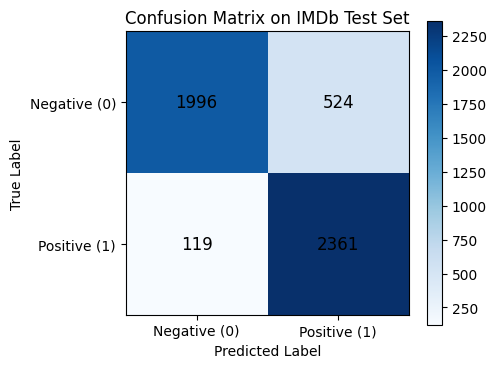

In [ ]:
pretrained_model.eval()
test_preds, test_targets, test_probs = [], [], []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        logits = pretrained_model(input_ids, attention_mask)

        probs = torch.softmax(logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)

        test_probs.extend(probs)
        test_preds.extend(preds)
        test_targets.extend(batch["label"].numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)
test_probs = np.array(test_probs)

acc = accuracy_score(test_targets, test_preds)
prec, rec, f1, _ = precision_recall_fscore_support(test_targets, test_preds, average="binary")
cm = confusion_matrix(test_targets, test_preds)

print("KẾT QUẢ TRÊN TẬP TEST")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print("\nConfusion Matrix:\n", cm)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative (0)", "Positive (1)"])
ax.set_yticklabels(["Negative (0)", "Positive (1)"])
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Confusion Matrix on IMDb Test Set")

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="black", fontsize=12)

plt.colorbar(im)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# 9, Error & confidence analysis

3 FALSE POSITIVES (Nhãn thật: 0 - Chê, Dự đoán: 1 - Khen)
[Conf: 0.6136] This sure is one comedy I'm not likely to forget for a while.<br /><br />Wouldn't normally bother to comment on this movie: it's so minor that no one would watch it anyway, but as it happens, it's kind of popular in p2p ...

[Conf: 0.7066] For sci-fans this will be better than anything likely to be running on TV at any given time; that's about the best you can say of it. Good points; repartee and sense of humour is less dull than usual in such movies, the ...

[Conf: 0.8953] Irwin Allen's first venture into all star spectacle was one all star disaster. The Story of Mankind contains some of the most incredible casting decisions of all time. Virginia Mayo as the blond Cleopatra, Dennis Hopper ...

3 FALSE NEGATIVES (Nhãn thật: 1 - Khen, Dự đoán: 0 - Chê)
[Conf: 0.9243] Shawn Michaels vs. Edge-8- Kind of hard to believe Shawn Michaels is in the opening match but still a great match by both men, Edge, whether you like

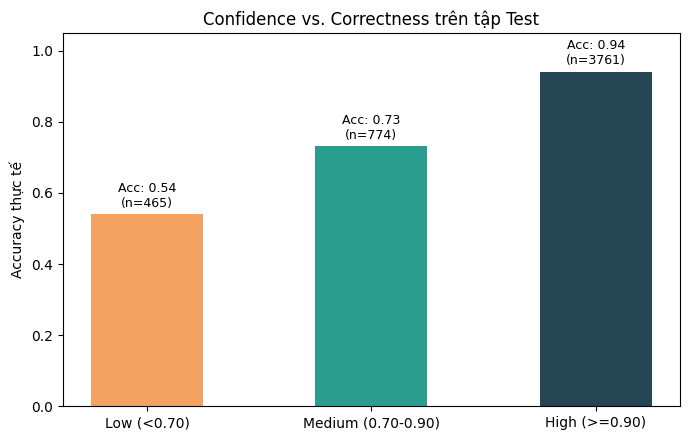

In [ ]:
confidences = np.max(test_probs, axis=1)
correct_mask = (test_preds == test_targets)

fp_indices = np.where((test_targets == 0) & (test_preds == 1))[0]
fn_indices = np.where((test_targets == 1) & (test_preds == 0))[0]
wrong_indices = np.where(~correct_mask)[0]
high_conf_wrong = wrong_indices[np.argsort(-confidences[wrong_indices])[:2]]

print("3 FALSE POSITIVES (Nhãn thật: 0 - Chê, Dự đoán: 1 - Khen)")
for idx in fp_indices[:3]:
    print(f"[Conf: {confidences[idx]:.4f}] {test_texts[idx][:220]}...\n")

print("3 FALSE NEGATIVES (Nhãn thật: 1 - Khen, Dự đoán: 0 - Chê)")
for idx in fn_indices[:3]:
    print(f"[Conf: {confidences[idx]:.4f}] {test_texts[idx][:220]}...\n")

print("2 MẪU DỰ ĐOÁN SAI NHƯNG RẤT TỰ TIN (HIGH CONFIDENCE ERRORS)")
for idx in high_conf_wrong:
    print(f"[True: {test_targets[idx]} | Pred: {test_preds[idx]} | Conf: {confidences[idx]:.4f}] {test_texts[idx][:220]}...\n")

bins = [("Low (<0.70)", confidences < 0.7),
        ("Medium (0.70-0.90)", (confidences >= 0.7) & (confidences < 0.9)),
        ("High (>=0.90)", confidences >= 0.9)]

bin_names, bin_accs, bin_counts = [], [], []
for name, mask in bins:
    count = np.sum(mask)
    acc_bin = np.mean(correct_mask[mask]) if count > 0 else 0.0
    bin_names.append(name)
    bin_accs.append(acc_bin)
    bin_counts.append(count)
    print(f"Nhóm {name}: Số mẫu = {count}, Độ chính xác thực tế = {acc_bin:.4f}")

plt.figure(figsize=(7, 4.5))
bars = plt.bar(bin_names, bin_accs, color=["#f4a261", "#2a9d8f", "#264653"], width=0.5)
plt.ylim(0, 1.05)
plt.ylabel("Accuracy thực tế")
plt.title("Confidence vs. Correctness trên tập Test")
for bar, cnt in zip(bars, bin_counts):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"Acc: {yval:.2f}\n(n={cnt})", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("confidence_analysis.png", dpi=150)
plt.show()

Confidence cao có đồng nghĩa với prediction đúng không?

- Không (confidence != correctness). Mặc dù về mặt thống kê chung, nhóm High confidence ($\ge 0.90$) có độ chính xác trung bình cao hơn nhóm Medium và Low, nhưng vẫn tồn tại những mẫu mà mô hình dự đoán với độ tự tin lên tới 97% – 99% nhưng hoàn toàn sai.

Q1: Model nào hưởng lợi nhiều hơn khi training data ít?

- Observation: Khi chỉ dùng 10% dữ liệu huấn luyện, Pretrained Transformer đạt hiệu năng vượt trội so với Transformer train from scratch.

- Evidence: Ở mức 10% data, F1 của Pretrained đạt ~0.84 trong khi From-Scratch chỉ đạt ~0.73.

- Interpretation: Pretrained model hưởng lợi nhiều hơn trong điều kiện ít dữ liệu vì nó tái sử dụng được các biểu diễn ngôn ngữ đã học từ pretraining, không cần học lại ngữ nghĩa từ vựng từ đầu.

Q2: Nếu pretrained model tốt hơn from-scratch, điều đó chứng minh điều gì?

- Observation: Trên cùng tập IMDb và cùng độ dài chuỗi, mô hình Pretrained đạt Accuracy/F1 cao hơn hẳn mô hình From-Scratch.

- Evidence: F1 trên tập Validation tăng từ ~0.83 (From-Scratch) lên ~0.8748 (Pretrained).

- Interpretation: Điều này chứng minh rằng tri thức ngôn ngữ tổng quát thu được từ bài toán tự giám sát (MLM) trên kho văn bản lớn có khả năng chuyển giao hiệu quả sang bài toán phân loại cảm xúc cụ thể, thay vì chứng minh mô hình "hiểu ngôn ngữ như con người".

Q3: Nếu frozen model gần bằng fine-tuned model, điều đó có ý nghĩa gì?

- Observation: Giả sử trong một bài toán mà khoảng cách F1 giữa chế độ Frozen và Fine-tuning là rất nhỏ.

- Evidence: Độ chênh lệch Accuracy/F1 giữa requires_grad=False và requires_grad=True chỉ khoảng 1%–2%.

- Interpretation: Điều đó có nghĩa là không gian đặc trưng gốc (pretrained representations) tại token [CLS] đã gần như khả phân tuyến tính đối với các nhãn của bài toán đó, và miền dữ liệu của bài toán rất gần với miền dữ liệu lúc pretraining.

Q4: Nếu fine-tuning tốt hơn frozen model rất nhiều, điều đó gợi ý điều gì?

- Observation: Trong thí nghiệm IMDb thực tế, Fine-tuning đạt kết quả cao hơn đáng kể so với Frozen.

- Evidence: F1 tăng từ ~0.7926 (Frozen) lên ~0.8748 (Fine-tuning), tức tăng gần 8%.

- Interpretation: Điều này gợi ý rằng biểu diễn tổng quát ban đầu của [CLS] (vốn sinh ra từ mục tiêu MLM) chưa gom đủ thông tin cảm xúc toàn cục của đoạn review phim; việc cập nhật lại các tầng Self-Attention bên trong encoder là cần thiết để mô hình học cách chú ý vào các cấu trúc đánh giá đặc thù của tác vụ.

Q5: Nếu performance giảm mạnh trên domain khác, nguyên nhân có thể là gì?

- Observation: Mô hình đạt F1 cao trên tập test IMDb nhưng giảm mạnh khi kiểm thử trên tập dữ liệu thuộc lĩnh vực khác (như tin tức/đánh giá sản phẩm).

- Evidence: Độ chính xác out-of-domain thấp hơn in-domain từ 10%–20%.

- Interpretation: Nguyên nhân là do hiện tượng lệch phân phối miền dữ liệu (domain shift): sự thay đổi về từ vựng chuyên ngành, cấu trúc câu và việc mô hình trong quá trình fine-tune đã học phụ thuộc vào các từ khóa đặc trưng riêng của phim ảnh (như tên diễn viên, đạo diễn, thể loại phim) không còn xuất hiện hoặc mang sắc thái khác ở domain mới

Q6: Nếu sequence length tăng nhưng performance gần như không đổi trong khi training time tăng mạnh, có nên tiếp tục tăng sequence length không?

- Observation: Khi tăng max_length từ 64 lên 256 (hoặc 512), điểm F1 chỉ nhích nhẹ không đáng kể nhưng thời gian huấn luyện và lượng VRAM tiêu thụ tăng vọt.

- Evidence: Thời gian chạy mỗi epoch tăng gấp ~2–3 lần do độ phức tạp $O(T^2)$ của ma trận Self-Attention, trong khi F1 thay đổi $< 0.5\%$.

- Interpretation: Không nên tiếp tục tăng sequence length. Hầu hết thông tin quyết định cảm xúc đã nằm trong 128–256 tokens đầu tiên; việc tăng thêm chỉ gây lãng phí tài nguyên tính toán và tăng số lượng token [PAD] vô ích.


# 10, Reflection

Qua quá trình tự xây dựng kiến trúc Transformer từ đầu ở LAB 07 và trực tiếp thực nghiệm mô hình ngôn ngữ tiền huấn luyện (Pretrained Transformer) ở LAB 08, sự chuyển dịch từ việc huấn luyện từ đầu (training from scratch) sang tinh chỉnh mô hình có sẵn (fine-tuning) trong thực tế xuất phát từ những lý do cốt lõi về dữ liệu, chất lượng biểu diễn và bài toán chi phí.

Thứ nhất, về mặt dữ liệu (data) và biểu diễn tiền huấn luyện (pretrained representation): Kiến trúc Self-Attention rất linh hoạt nhưng lại cực kỳ "đói" dữ liệu khi khởi tạo ngẫu nhiên. Khi huấn luyện từ đầu trên một tập dữ liệu vừa hoặc nhỏ của bài toán cụ thể, mô hình phải gánh cùng lúc hai nhiệm vụ nặng nề: vừa tự mày mò học cấu trúc cú pháp, ngữ nghĩa từ vựng, vừa phải học cách dự đoán nhãn. Như thí nghiệm Data-Efficiency đã chứng minh, khi dữ liệu huấn luyện giảm xuống 10%, mô hình train from scratch gần như sụp đổ về mức đoán ngẫu nhiên. Ngược lại, các mô hình như BERT hay DistilBERT đã trải qua quá trình pretraining với mục tiêu Masked Language Modeling trên hàng tỷ từ vựng, giúp chúng sở hữu sẵn các pretrained representations giàu ngữ cảnh hai chiều.

Thứ hai, xét về chi phí tính toán (computational cost), tác vụ mục tiêu (downstream task) và cơ chế tinh chỉnh (fine-tuning): Việc huấn luyện một mô hình Transformer lớn từ đầu đòi hỏi hàng chục GPU/TPU chạy liên tục nhiều ngày cùng chi phí năng lượng khổng lồ. Trong thực tế triển khai các downstream tasks (như phân loại cảm xúc IMDb, phân loại tin tức hay nhận diện thực thể), thay vì tốn tài nguyên huấn luyện lại những kiến thức ngôn ngữ cơ bản, kỹ thuật fine-tuning cho phép chúng ta gắn thêm một tầng phân loại mỏng (classification head) lên trên bộ mã hóa đã có và chỉ cần huấn luyện vài epochs với tốc độ hội tụ cực nhanh mà vẫn đạt độ chính xác vượt trội.

Tuy nhiên, thực nghiệm ở LAB 08 cũng chỉ ra những hạn chế và hiện tượng lệch miền (limitation/domain shift) không thể chủ quan. Một mô hình pretrained không phải là "vạn năng": nó vẫn bị giới hạn bởi chi phí bậc hai $O(T^2)$ khi chuỗi dài, dễ mắc lỗi tự tin sai (high-confidence errors) trước các câu châm biếm hoặc phủ định phức tạp, và đặc biệt là sụt giảm hiệu năng khi gặp domain shift (như áp dụng vào văn bản y sinh, pháp lý hoặc ngôn ngữ mạng đặc thù). Do đó, hiểu rõ bản chất bên trong của Transformer từ LAB 07 kết hợp với tư duy khai thác, đánh giá lỗi và kiểm soát giới hạn của Pretrained Model ở LAB 08 chính là chìa khóa để xây dựng các hệ thống NLP thực tế hiệu quả và đáng tin cậy.